In [48]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '40fb3ec4'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '4e11ca1b'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '9e1efe23'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/michaeladennis/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

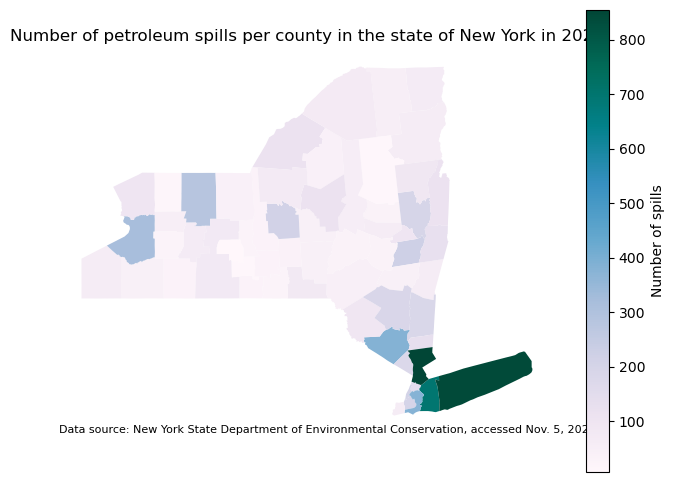

In [85]:
# FINAL CODE
# import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# import data
fp = os.path.join('data', 'Spill_Incidents_20261105.csv')
spills = pd.read_csv(fp)



fp2 = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties =  gpd.read_file(fp2)

# clean
spills.columns = spills.columns.str.strip().str.lower().str.replace(' - ', '_').str.replace(' ', '_')

# use .astype to change the data types in each of the columns that may give us trouble later
# spill date
spills['spill_date'] = spills['spill_date'].astype('datetime64[ms]')

# close date
spills['close_date'] = spills['close_date'].astype('datetime64[ms]')

# spill_number as chr
spills['spill_number'] = spills['spill_number'].astype('object')

# sis_code as chr
spills['swis_code'] = spills['swis_code'].astype('object')

# received_date as date
spills['received_date'] = spills['received_date'].astype('datetime64[ms]')

# quantity as int64
spills['quantity'] = spills['quantity'].str.replace(',', '') # remove commas so we can convert to numeric
spills['quantity'] = spills['quantity'].astype('float64')

# index to the `material_family` column to filter to just `Petroleum` spills and save to a new variable
petroleum = spills[spills['material_family'] == ('Petroleum')]
# filter to dats just between Jan 1, 2023 and Dec 31, 2023 using booleans
petr_23 = petroleum[(petroleum['spill_date'] >= '2023-01-01') & (petroleum['spill_date'] <= '2023-12-31')]

# number of petroleum spills per county from January to December 2023.
spills_per_county = petr_23.groupby('county')['spill_number'].nunique()
spills_per_county = spills_per_county.reset_index()

spills_per_county = spills_per_county.rename(columns={ 'county' : 'county',
  'spill_number': 'n_spills'})

counties.columns = counties.columns.str.lower().str.strip()
# make all of the column names lower case and strip and trailing/starting spaces using .str strip and lower

# Select all the counties for the state of New York
ny_counties = counties[counties['statefp'] == '36']

# update St Lawrence
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

# merge
spills_per_county = spills_per_county.rename(columns={ 'county' : 'name',
  'spill_number': 'n_spills'})
spills_ny = pd.merge(spills_per_county, ny_counties, how='inner', on='name')

# update reservations
tusc = spills_per_county.loc[spills_per_county['name'] == 'Tuscarora Indian Reservation', 'name']
onon_res = spills_per_county.loc[spills_per_county['name'] == 'Onondaga Indian Reservation', 'name']



ny_spills.loc[ny_spills['name'] == 'Tuscarora Indian Reservation', 'name'] = 'Niagara'
ny_spills.loc[ny_spills['name'] == 'Onondaga Indian Reservation', 'name'] = 'Onondaga'

ny_spills['n_spills'] = ny_spills['n_spills'].astype('float64')
# plot
ny_spills = gpd.GeoDataFrame(ny_spills, geometry='geometry')

fig, ax = plt.subplots(figsize=(8, 6))

ny_spills.plot(ax=ax,
               column='n_spills',          # what should the colors represent?
               cmap='PuBuGn',            # pick a colormap
               legend_kwds={'label': 'Number of spills'},
               legend=True,       # optional: county borders
               linewidth=0.5)

ax.set_title('Number of petroleum spills per county in the state of New York in 2023')
ax.axis('off')

ax.annotate('Data source: New York State Department of Environmental Conservation, accessed Nov. 5, 2026',
            xy=(0, 0), xycoords='axes fraction',
            fontsize=8)

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

Spilling incidents: This data set contains information about environmental spills within New York. It contains information about the cause, date, setting, and other identifying aspects of each recorded spill. This data comes from [data.ny.gov](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data), accessed Nov. 5, 2026.

TIGER shape files: This data contains the outlines for all of the U.S. states and entities. The shapefiles also contain point and line geometries for geographical and sociopolitical boundaries as well, such as district outlines and rivers. This data comes from [census.gov](https://www.census.gov/cgi-bin/geo/shapefiles/index.php), accessed Nov 5. 2026.

## 3. Import libraries

In [50]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [51]:
fp = os.path.join('data', 'Spill_Incidents_20261105.csv')
spills = pd.read_csv(fp)


fp2 = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties =  gpd.read_file(fp2)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [52]:
#a. Check the dataframe's head
spills.head()
# using .head() we can see the first few rows of the data frame
# here we can see that the spills dataframe contains identifying information on different spills throughout new york

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [53]:
#b. Check the data types of the columns
spills.info()
# .info allows us to see the column name, type, and number of null vlues. Here we see that most column types are objects with some int64.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574781 entries, 0 to 574780
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574781 non-null  int64 
 1   Program Facility Name  574775 non-null  object
 2   Street 1               574647 non-null  object
 3   Street 2               44737 non-null   object
 4   Locality               573630 non-null  object
 5   County                 574781 non-null  object
 6   ZIP Code               57928 non-null   object
 7   SWIS Code              574781 non-null  int64 
 8   DEC Region             574781 non-null  int64 
 9   Spill Date             574630 non-null  object
 10  Received Date          574278 non-null  object
 11  Contributing Factor    574781 non-null  object
 12  Waterbody              47993 non-null   object
 13  Source                 574781 non-null  object
 14  Close Date             562399 non-null  object
 15  

In [54]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()
# using .unique after indexing the column shows us all of the unique entries for the column
# here we see that there are only 4 unique values in the `material_family` column

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [55]:
#d. Check the unique values in the `county` column
print(spills['County'].nunique())
# using .nunique after indexing the column shows us the number of unique values in the `County` column, 87
print(spills['County'].unique())
#  .unique after indexing the column shows us all of the unique entries for the column


87
['Westchester' 'Queens' 'Bronx' 'Sullivan' 'Cortland' 'New York' 'Ulster'
 'Kings' 'Orange' 'Dutchess' 'Onondaga' 'Saratoga' 'Cayuga' 'Oswego'
 'Warren' 'Niagara' 'Rockland' 'Nassau' 'Jefferson' 'Schenectady' 'Albany'
 'Monroe' 'Schuyler' 'St Lawrence' 'Richmond' 'Clinton' 'Lewis' 'Essex'
 'Chenango' 'Erie' 'Livingston' 'Oneida' 'Wayne' 'Suffolk' 'Orleans'
 'Ontario' 'Genesee' 'Otsego' 'Tompkins' 'Madison' 'Chemung' 'Seneca'
 'Broome' 'Hamilton' 'Washington' 'Steuben' 'Rensselaer' 'Franklin'
 'Columbia' 'Fulton' 'Herkimer' 'Schoharie' 'Montgomery' 'Putnam'
 'Delaware' 'New Jersey - Region 2' 'Tioga' 'Chautauqua' 'Cattaraugus'
 'Wyoming' 'Yates' 'Greene' 'Pennsylvania - Region 9' 'Allegany'
 'New Jersey - Region 3 (N)' 'Cattaraugus Indian Reservation'
 'Connecticut - Region 3 (T)' 'New Jersey - Region 3 (T)'
 'Canada - Region 6' 'Canada - Region 9' 'Pennsylvania - Region 8'
 'Vermont - Region 5 (R)' 'Vermont - Region 4'
 'Connecticut - Region 3 (N)' 'Pennsylvania - Region 3'
 'Tuscar

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [56]:
spills.columns = spills.columns.str.strip().str.lower().str.replace(' - ', '_').str.replace(' ', '_')
spills.columns
# use the various .str commands to remove all spaces, replace hyphens with underscores, and to make eerything lowercase to ensure we are following snake_case protocols

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

In [57]:
spills.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [58]:
# use .astype to change the data types in each of the columns that may give us trouble later
# spill date
spills['spill_date'] = spills['spill_date'].astype('datetime64[ms]')

# close date
spills['close_date'] = spills['close_date'].astype('datetime64[ms]')

# spill_number as chr
spills['spill_number'] = spills['spill_number'].astype('object')

# sis_code as chr
spills['swis_code'] = spills['swis_code'].astype('object')

# received_date as date
spills['received_date'] = spills['received_date'].astype('datetime64[ms]')

# quantity as int64
spills['quantity'] = spills['quantity'].str.replace(',', '') # remove commas so we can convert to numeric
spills['quantity'] = spills['quantity'].astype('float64')
spills.info() # check that it worked




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574781 entries, 0 to 574780
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   spill_number           574781 non-null  object        
 1   program_facility_name  574775 non-null  object        
 2   street_1               574647 non-null  object        
 3   street_2               44737 non-null   object        
 4   locality               573630 non-null  object        
 5   county                 574781 non-null  object        
 6   zip_code               57928 non-null   object        
 7   swis_code              574781 non-null  object        
 8   dec_region             574781 non-null  int64         
 9   spill_date             574630 non-null  datetime64[ms]
 10  received_date          574278 non-null  datetime64[ms]
 11  contributing_factor    574781 non-null  object        
 12  waterbody              47993 non-null   obje

IKJ:NL <!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [59]:
# index to the `material_family` column to filter to just `Petroleum` spills and save to a new variable
petroleum = spills[spills['material_family'] == ('Petroleum')]
# filter to dats just between Jan 1, 2023 and Dec 31, 2023 using booleans
petr_23 = petroleum[(petroleum['spill_date'] >= '2023-01-01') & (petroleum['spill_date'] <= '2023-12-31')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [60]:
print(f"Unique years in petr_23 {petr_23['spill_date'].dt.year.unique()}")
print(f"Earliest date: {petr_23['spill_date'].min()}")
print(f"Latest date: {petr_23['spill_date'].max()}")

Unique years in petr_23 [2023]
Earliest date: 2023-01-01 00:00:00
Latest date: 2023-12-31 00:00:00


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [61]:
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

These numbers might be different because of repeat spill entry, or spill cases that were reopened due to insufficient resoltuons. For example, if a spill occurred, was closed, and then more spill damage was found a month later, the unique spill case could have been reopened.

In [62]:
print(f"Number of rows in petr_23: {len(petr_23)}")
print(f"Number of unique spills: {petr_23['spill_number'].nunique()}")

Number of rows in petr_23: 8468
Number of unique spills: 8228


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [63]:
spills_per_county = petr_23.groupby('county')['spill_number'].nunique()
spills_per_county = spills_per_county.reset_index()

spills_per_county = spills_per_county.rename(columns={ 'county' : 'county',
  'spill_number': 'n_spills'})
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [64]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [65]:
#  a. Check the geo-dataframe's head
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [66]:
# b. Check the data types of the columns
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   3235 non-null   object  
 1   COUNTYFP  3235 non-null   object  
 2   COUNTYNS  3235 non-null   object  
 3   GEOID     3235 non-null   object  
 4   GEOIDFQ   3235 non-null   object  
 5   NAME      3235 non-null   object  
 6   NAMELSAD  3235 non-null   object  
 7   LSAD      3235 non-null   object  
 8   CLASSFP   3235 non-null   object  
 9   MTFCC     3235 non-null   object  
 10  CSAFP     1341 non-null   object  
 11  CBSAFP    1915 non-null   object  
 12  METDIVFP  139 non-null    object  
 13  FUNCSTAT  3235 non-null   object  
 14  ALAND     3235 non-null   int64   
 15  AWATER    3235 non-null   int64   
 16  INTPTLAT  3235 non-null   object  
 17  INTPTLON  3235 non-null   object  
 18  geometry  3235 non-null   geometry
dtypes: geometry(1), int64(2), object(16)
mem

In [67]:
# c. Check the geo-dataframe's CRS
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

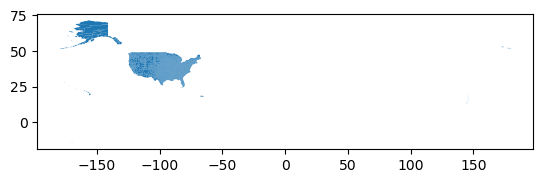

In [68]:
# d. Plot the geo-dataframe
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [69]:
counties.columns = counties.columns.str.lower().str.strip()
# make all of the column names lower case and strip and trailing/starting spaces using .str strip and lower

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

New Yorks fips (`statefp`) state code is 36, from [cornell.edu](https://pad.human.cornell.edu/maps2010/maps/ReferenceMaps.pdf).

<Axes: >

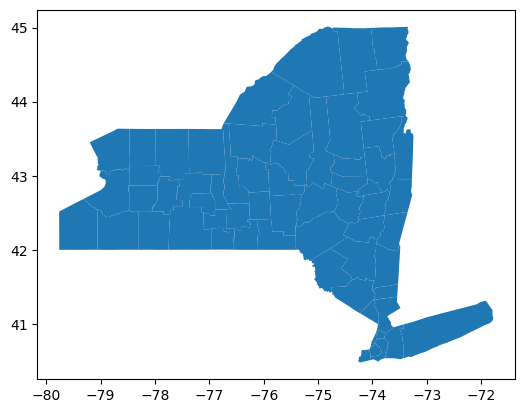

In [70]:

ny_counties = counties[counties['statefp'] == '36']
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [71]:
print(ny_counties['name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [72]:
print(spills_per_county['county'].unique())

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [73]:
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [74]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [75]:
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [76]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [77]:
# e. 
print(f"Number of spills in Tuscarora Indian Reservation: {spills_per_county[spills_per_county['county'] == 'Tuscarora Indian Reservation']['n_spills']}")
print(f"Number of spills in Onondaga Indian Reservation: {spills_per_county[spills_per_county['county'] == 'Onondaga Indian Reservation']['n_spills']}")

Number of spills in Tuscarora Indian Reservation: 58    2
Name: n_spills, dtype: int64
Number of spills in Onondaga Indian Reservation: 35    1
Name: n_spills, dtype: int64


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [78]:
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'
assert (spills_per_county['county'] != 'St Lawerence').all()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [79]:
# a 
spills_per_county = spills_per_county.rename(columns={ 'county' : 'name',
  'spill_number': 'n_spills'})
spills_ny = pd.merge(spills_per_county, ny_counties, how='inner', on='name')


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [80]:
ny_spills = spills_ny

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [81]:
# Find rows in spills_per_county whose county did not make it into the join
dropped = spills_per_county[~spills_per_county['name'].isin(ny_spills['name'])]
dropped

,name,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

It does imapct the information we report, but it may not show up on the map. The names of these counties seem like things that plausibly might not show up on a boundary map of all of New York's counties.


<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [82]:
tusc = spills_per_county.loc[spills_per_county['name'] == 'Tuscarora Indian Reservation', 'name']
onon_res = spills_per_county.loc[spills_per_county['name'] == 'Onondaga Indian Reservation', 'name']


ny_spills.loc[ny_spills['name'] == 'Tuscarora Indian Reservation', 'name'] = 'Niagara'
ny_spills.loc[ny_spills['name'] == 'Onondaga Indian Reservation', 'name'] = 'Onondaga'


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



In [83]:
ny_spills['n_spills'] = ny_spills['n_spills'].astype('float64')


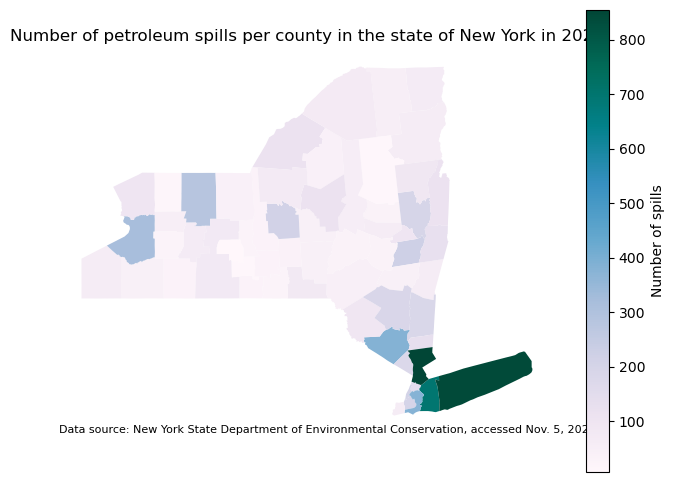

In [84]:
ny_spills = gpd.GeoDataFrame(ny_spills, geometry='geometry')

fig, ax = plt.subplots(figsize=(8, 6))

ny_spills.plot(ax=ax,
               column='n_spills',          # what should the colors represent?
               cmap='PuBuGn',            # pick a colormap
               legend_kwds={'label': 'Number of spills'},
               legend=True,       # optional: county borders
               linewidth=0.5)

ax.set_title('Number of petroleum spills per county in the state of New York in 2023')
ax.axis('off')

ax.annotate('Data source: New York State Department of Environmental Conservation, accessed Nov. 5, 2026',
            xy=(0, 0), xycoords='axes fraction',
            fontsize=8)

plt.show()


b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.